### data loading and merging

In [1]:
import numpy as np
import pandas as pd
import re
import nltk
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sentence_transformers import SentenceTransformer, util
import torch
from sklearn.model_selection import KFold
import lightgbm as lgb
import matplotlib.pyplot as plt
import pickle


stemmer = PorterStemmer()
print("--- Starting Advanced Pipeline ---")
print("Loading all datasets...")
try:
    # 1. Load the raw CSV files
    train_df = pd.read_csv('data/train.csv', encoding='ISO-8859-1')
    desc_df = pd.read_csv('data/product_descriptions.csv', encoding='ISO-8859-1')
    attr_df = pd.read_csv('data/attributes.csv', encoding='ISO-8859-1')
    
    print(f"Base Train Shape: {train_df.shape}")
    print(f"Descriptions Shape: {desc_df.shape}")
    print(f"Attributes Shape: {attr_df.shape}")
    
    
    print("\nExtracting brand information from attributes...")
    brand_df = attr_df[attr_df['name'] == 'MFG Brand Name'].copy()
    brand_df = brand_df.rename(columns={'value': 'product_brand'})
    brand_df = brand_df[['product_uid', 'product_brand']].drop_duplicates(subset=['product_uid'])
    
    
    print("Merging all datasets together...")
    
    df = pd.merge(train_df, desc_df, on='product_uid', how='left')
    
    df = pd.merge(df, brand_df, on='product_uid', how='left')
    
    
    df['product_brand'] = df['product_brand'].fillna('Unknown')
    df['product_description'] = df['product_description'].fillna('')
    
    print("\nFinal Integrated Dataset Shape:", df.shape)
    print("\nFirst 3 rows of the advanced dataset:")
    print(df[['product_uid', 'search_term', 'product_title', 'product_brand']].head(3))

except FileNotFoundError as e:
    print(f"Error: Please ensure 'train.csv', 'product_descriptions.csv', and 'attributes.csv' are in the same folder. Detailed error: {e}")

--- Starting Advanced Pipeline ---
Loading all datasets...
Base Train Shape: (74067, 5)
Descriptions Shape: (124428, 2)
Attributes Shape: (2044803, 3)

Extracting brand information from attributes...
Merging all datasets together...

Final Integrated Dataset Shape: (74067, 7)

First 3 rows of the advanced dataset:
   product_uid    search_term  \
0       100001  angle bracket   
1       100001      l bracket   
2       100002      deck over   

                                       product_title  \
0                  Simpson Strong-Tie 12-Gauge Angle   
1                  Simpson Strong-Tie 12-Gauge Angle   
2  BEHR Premium Textured DeckOver 1-gal. #SC-141 ...   

                    product_brand  
0              Simpson Strong-Tie  
1              Simpson Strong-Tie  
2  BEHR Premium Textured DeckOver  


### text preprocessing

In [3]:
home_depot_synonyms = {
    "galv": "galvanized",
    "gal": "gallon",
    "cu ft": "cubic feet",
    "ft": "foot",
    "in": "inch",
    "in.": "inch",
    "lbs": "pound",
    "lb": "pound",
    "w/": "with",
    "w/o": "without",
    "whirlpool": "whirlpool",
    "wirlpool": "whirlpool",
    "anderson": "andersen",
    "sheetrock": "drywall"
}


def clean_text_advanced(text):
    if isinstance(text, str):
        
        text = text.lower()
        
        
        words = text.split()
        words = [home_depot_synonyms[w] if w in home_depot_synonyms else w for w in words]
        text = " ".join(words)
        
        
        text = re.sub(r'(\d+)\s*(inches|inch|in|in\.)(?=\b|\d)', r'\1 inch ', text)
        text = re.sub(r'(\d+)\s*(feet|foot|ft|ft\.)(?=\b|\d)', r'\1 foot ', text)
        text = re.sub(r'(\d+)\s*(pounds|pound|lbs|lb|lb\.)(?=\b|\d)', r'\1 pound ', text)
        text = re.sub(r'(\d+)\s*(volts|volt|v)(?=\b|\d)', r'\1 volt ', text)
        text = re.sub(r'(\d+)\s*(watts|watt|w)(?=\b|\d)', r'\1 watt ', text)
        text = re.sub(r'(\d+)(x|\s*x\s*)(\d+)', r'\1 x \3', text)
        
        
        words = text.split()
        stemmed = [stemmer.stem(w) for w in words]
        
        return " ".join(stemmed)
    return ""

print("Applying advanced text cleaning across all text fields...")

df['clean_search_term'] = df['search_term'].apply(clean_text_advanced)
df['clean_product_title'] = df['product_title'].apply(clean_text_advanced)
df['clean_product_description'] = df['product_description'].apply(clean_text_advanced)
df['clean_product_brand'] = df['product_brand'].apply(clean_text_advanced)

print("Advanced text cleaning completed!")
# Verify the brand cleaning
print("\nSample of original vs cleaned brand:")
print(df[['product_brand', 'clean_product_brand']].head(3))

Applying advanced text cleaning across all text fields...
Advanced text cleaning completed!

Sample of original vs cleaned brand:
                    product_brand         clean_product_brand
0              Simpson Strong-Tie           simpson strong-ti
1              Simpson Strong-Tie           simpson strong-ti
2  BEHR Premium Textured DeckOver  behr premium textur deckov


### feature eng

In [ ]:
def count_common_words(search, target):
    if isinstance(search, str) and isinstance(target, str):
        search_words = set(search.split())
        target_words = set(target.split())
        return len(search_words.intersection(target_words))
    return 0

def get_jaccard_similarity(str1, str2):
    if isinstance(str1, str) and isinstance(str2, str):
        set1 = set(str1.split())
        set2 = set(str2.split())
        if not set1 or not set2: 
            return 0.0
        return float(len(set1.intersection(set2))) / len(set1.union(set2))
    return 0.0

print("Extracting advanced features (including Brand Matching)...")


df['search_len'] = df['clean_search_term'].apply(lambda x: len(x.split()))

df['word_match_title'] = df.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_title']), axis=1)
df['word_match_desc'] = df.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_description']), axis=1)
df['word_match_brand'] = df.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_brand']), axis=1)

df['ratio_title'] = df['word_match_title'] / (df['search_len'] + 1e-5)
df['ratio_desc'] = df['word_match_desc'] / (df['search_len'] + 1e-5)
df['ratio_brand'] = df['word_match_brand'] / (df['search_len'] + 1e-5)

df['jaccard_title'] = df.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_title']), axis=1)
df['jaccard_desc'] = df.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_description']), axis=1)
df['jaccard_brand'] = df.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_brand']), axis=1)

print("Advanced feature extraction completed successfully!")

print(df[['clean_search_term', 'clean_product_brand', 'word_match_brand', 'ratio_brand', 'jaccard_brand']].head())

Extracting advanced features (including Brand Matching)...
Advanced feature extraction completed successfully!
    clean_search_term         clean_product_brand  word_match_brand  \
0        angl bracket          simpson strong tie                 0   
1           l bracket          simpson strong tie                 0   
2           deck over  behr premium textur deckov                 0   
3    rain shower head                       delta                 0   
4  shower onli faucet                       delta                 0   

   ratio_brand  jaccard_brand  
0          0.0            0.0  
1          0.0            0.0  
2          0.0            0.0  
3          0.0            0.0  
4          0.0            0.0  


 ### TF-IDF & Cosine simlarity

In [ ]:
print("Calculating TF-IDF and Cosine Similarities")


combined_corpus = df['clean_product_title'] + " " + df['clean_product_description']


tfidf = TfidfVectorizer(max_features=15000, stop_words='english')
tfidf.fit(combined_corpus)


def get_cosine_sim_batch(vectorizer, search_series, target_series):
    # Transform strings into TF-IDF vectors
    search_vectors = vectorizer.transform(search_series)
    target_vectors = vectorizer.transform(target_series)
    
    
    sim_scores = np.sum(search_vectors.multiply(target_vectors), axis=1)
    return np.array(sim_scores).flatten()


df['tfidf_cos_title'] = get_cosine_sim_batch(tfidf, df['clean_search_term'], df['clean_product_title'])


df['tfidf_cos_desc'] = get_cosine_sim_batch(tfidf, df['clean_search_term'], df['clean_product_description'])

print("TF-IDF Cosine Similarity features extracted successfully!")


print(df[['clean_search_term', 'tfidf_cos_title', 'tfidf_cos_desc']].head())

Calculating TF-IDF and Cosine Similarities
TF-IDF Cosine Similarity features extracted successfully!
    clean_search_term  tfidf_cos_title  tfidf_cos_desc
0        angl bracket         0.272066        0.202337
1           l bracket         0.000000        0.000000
2           deck over         0.000000        0.211652
3    rain shower head         0.149838        0.053487
4  shower onli faucet         0.437650        0.156226


### Modeling

In [ ]:
print("Preparing feature matrix...")


advanced_features = [
    'search_len', 
    'word_match_title', 'word_match_desc', 'word_match_brand',
    'ratio_title', 'ratio_desc', 'ratio_brand',
    'jaccard_title', 'jaccard_desc', 'jaccard_brand',
    'tfidf_cos_title', 'tfidf_cos_desc'
]

X = df[advanced_features]
y = df['relevance']


X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train size: {X_train.shape[0]} | Validation size: {X_val.shape[0]}")


print("\nTraining the Random Forest Regressor...")
advanced_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
advanced_model.fit(X_train, y_train)


y_pred = advanced_model.predict(X_val)
advanced_rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"\nModel Training Completed")
print(f"Validation RMSE: {advanced_rmse:.4f}")

Preparing feature matrix...
Train size: 59253 | Validation size: 14814

Training the Random Forest Regressor...

Model Training Completed
Validation RMSE: 0.4743


In [ ]:
print("Loading pre-trained Mini-BERT model (all-MiniLM-L6-v2)...")

semantic_model = SentenceTransformer('all-MiniLM-L6-v2')


print("Encoding search terms and product titles into semantic vectors.")


search_terms = df['clean_search_term'].tolist()
product_titles = df['clean_product_title'].tolist()


search_embeddings = semantic_model.encode(search_terms, convert_to_tensor=True, show_progress_bar=True)
title_embeddings = semantic_model.encode(product_titles, convert_to_tensor=True, show_progress_bar=True)

print("Calculating Semantic Cosine Similarity via BERT...")

bert_sim_scores = []


for i in range(len(search_terms)):
    
    sim = util.cos_sim(search_embeddings[i], title_embeddings[i]).item()
    bert_sim_scores.append(sim)


df['bert_semantic_title_sim'] = bert_sim_scores

print("Semantic features extracted successfully!")
print(df[['clean_search_term', 'clean_product_title', 'bert_semantic_title_sim']].head())

Loading pre-trained Mini-BERT model (all-MiniLM-L6-v2)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding search terms and product titles into semantic vectors... This may take a moment.


Batches:   0%|          | 0/2315 [00:00<?, ?it/s]

Batches:   0%|          | 0/2315 [00:00<?, ?it/s]

Calculating Semantic Cosine Similarity via BERT...
Semantic features extracted successfully!
    clean_search_term                                clean_product_title  \
0        angl bracket                    simpson strong tie 12 gaug angl   
1           l bracket                    simpson strong tie 12 gaug angl   
2           deck over  behr premium textur deckov 1 gal sc 141 tugboa...   
3    rain shower head  delta vero 1 handl shower onli faucet trim kit...   
4  shower onli faucet  delta vero 1 handl shower onli faucet trim kit...   

   bert_semantic_title_sim  
0                 0.322789  
1                 0.293150  
2                 0.318100  
3                 0.268487  
4                 0.581535  


In [ ]:
X_arr = np.array(X_train)  
y_arr = np.array(y_train)  

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_scores = []

print("Starting 5-Fold cross validation")
for fold, (train_idx, val_idx) in enumerate(kf.split(X_arr, y_arr), 1):
    X_tr, X_val = X_arr[train_idx], X_arr[val_idx]
    y_tr, y_val = y_arr[train_idx], y_arr[val_idx]
    
    
    fold_model = lgb.LGBMRegressor(n_estimators=100, random_state=42, verbose=-1)
    fold_model.fit(X_tr, y_tr)
    
   
    preds = fold_model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    rmse_scores.append(rmse)
    print(f"Fold {fold} - RMSE (خطای مدل): {rmse:.4f}")

print("\nFinal cv results")
print(f"Average RMSE across all folds: {np.mean(rmse_scores):.4f}")

Starting 5-Fold cross validation


e:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "e:\Anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "e:\Anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass

Fold 1 - RMSE (خطای مدل): 0.4747


e:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 2 - RMSE (خطای مدل): 0.4787


e:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 3 - RMSE (خطای مدل): 0.4756


e:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 4 - RMSE (خطای مدل): 0.4785
Fold 5 - RMSE (خطای مدل): 0.4743

Final cv results
Average RMSE across all folds: 0.4764


e:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
print("Preparing complete SOTA feature matrix...")

sota_features = [
    'search_len', 
    'word_match_title', 'word_match_desc', 'word_match_brand',
    'ratio_title', 'ratio_desc', 'ratio_brand',
    'jaccard_title', 'jaccard_desc', 'jaccard_brand',
    'tfidf_cos_title', 'tfidf_cos_desc',
    'bert_semantic_title_sim' 
]

X = df[sota_features]
y = df['relevance']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train Dataset Size: {X_train.shape[0]} | Validation Dataset Size: {X_val.shape[0]}")

print("\nTraining the LightGBM Model...")
sota_model = lgb.LGBMRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=7,
    random_state=42,
    n_jobs=-1
)

sota_model.fit(X_train, y_train)


y_pred = sota_model.predict(X_val)
sota_rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"\nModel Training Completed ---")
print(f"Validation RMSE: {sota_rmse:.4f}")

Preparing complete SOTA feature matrix...
Train Dataset Size: 59253 | Validation Dataset Size: 14814

Training the LightGBM Model...

Model Training Completed ---
Validation RMSE: 0.4629


<Figure size 1000x600 with 0 Axes>

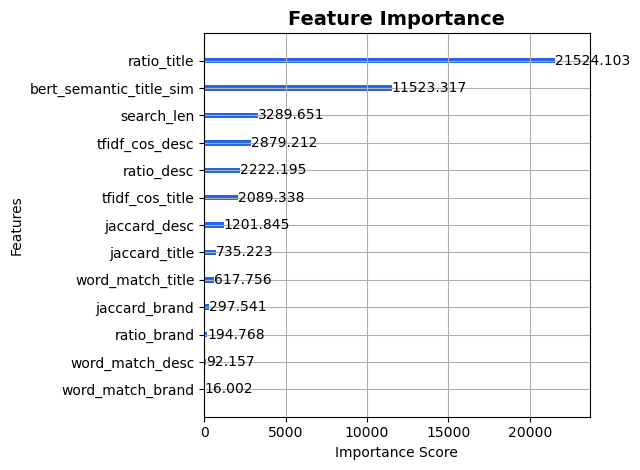

In [ ]:
plt.figure(figsize=(10, 6))
lgb.plot_importance(sota_model, max_num_features=13, importance_type='gain', color='#2563EB')
plt.title('Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()


plt.savefig('feature_importance.png', dpi=300)
plt.show()

### saving the model

In [ ]:
print("Saving all pipeline components...")


sota_pipeline_data = {
    'trained_model': sota_model,
    'tfidf_vectorizer': tfidf,
    'features': sota_features
}


with open('ir_sota_search_model.pkl', 'wb') as f:
    pickle.dump(sota_pipeline_data, f)


semantic_model.save('local_mini_bert_model')

print("\nAll SOTA components saved successfully!")
print("- 'ir_sota_search_model.pkl' (Model & Text Features)")
print("- 'local_mini_bert_model/' (Local BERT Weights directory)")

Saving all pipeline components...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


All SOTA components saved successfully!
- 'ir_sota_search_model.pkl' (Model & Text Features)
- 'local_mini_bert_model/' (Local BERT Weights directory)


In [ ]:
print("--- Starting Inference on Test Dataset ---")

try:
    df_test = pd.read_csv('data/test.csv', encoding='ISO-8859-1')
    print(f"Loaded test.csv successfully. Shape: {df_test.shape}")
except FileNotFoundError:
    print("Error: test.csv not found in the directory! Please place it next to the notebook.")
    exit()


print("Merging test data with descriptions and extracted brands...")
df_test = pd.merge(df_test, desc_df, on='product_uid', how='left')
df_test = pd.merge(df_test, brand_df, on='product_uid', how='left')


df_test['product_description'] = df_test['product_description'].fillna("")
df_test['product_brand'] = df_test['product_brand'].fillna("Unknown")


print("Cleaning text fields for test set...")
df_test['clean_search_term'] = df_test['search_term'].apply(clean_text_advanced)
df_test['clean_product_title'] = df_test['product_title'].apply(clean_text_advanced)
df_test['clean_product_description'] = df_test['product_description'].apply(clean_text_advanced)
df_test['clean_product_brand'] = df_test['product_brand'].apply(clean_text_advanced)


print("Extracting structural features...")
df_test['search_len'] = df_test['clean_search_term'].apply(lambda x: len(x.split()))
df_test['word_match_title'] = df_test.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_title']), axis=1)
df_test['word_match_desc'] = df_test.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_description']), axis=1)
df_test['word_match_brand'] = df_test.apply(lambda row: count_common_words(row['clean_search_term'], row['clean_product_brand']), axis=1)

df_test['ratio_title'] = df_test['word_match_title'] / (df_test['search_len'] + 1e-5)
df_test['ratio_desc'] = df_test['word_match_desc'] / (df_test['search_len'] + 1e-5)
df_test['ratio_brand'] = df_test['word_match_brand'] / (df_test['search_len'] + 1e-5)

df_test['jaccard_title'] = df_test.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_title']), axis=1)
df_test['jaccard_desc'] = df_test.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_description']), axis=1)
df_test['jaccard_brand'] = df_test.apply(lambda row: get_jaccard_similarity(row['clean_search_term'], row['clean_product_brand']), axis=1)


print("Calculating TF-IDF similarities for test set...")
df_test['tfidf_cos_title'] = get_cosine_sim_batch(tfidf, df_test['clean_search_term'], df_test['clean_product_title'])
df_test['tfidf_cos_desc'] = get_cosine_sim_batch(tfidf, df_test['clean_search_term'], df_test['clean_product_description'])


print("Encoding test data with BERT (This might take 2-3 minutes)...")
test_search_emb = semantic_model.encode(df_test['clean_search_term'].tolist(), convert_to_tensor=True, show_progress_bar=True)
test_title_emb = semantic_model.encode(df_test['clean_product_title'].tolist(), convert_to_tensor=True, show_progress_bar=True)

test_bert_sims = []
for i in range(len(df_test)):
    sim = util.cos_sim(test_search_emb[i], test_title_emb[i]).item()
    test_bert_sims.append(sim)
df_test['bert_semantic_title_sim'] = test_bert_sims

print("\nRunning LightGBM model over test features...")
X_test = df_test[sota_features] 
test_predictions = sota_model.predict(X_test)
test_predictions = np.clip(test_predictions, 1.0, 3.0)


submission = pd.DataFrame({
    'id': df_test['id'],
    'relevance': test_predictions
})

submission.to_csv('submission.csv', index=False)
print("\n--- Inference Completed Successfully! ---")
print("Saved final predicted outputs as 'submission.csv'. Ready for deployment or evaluation.")
print(submission.head())

--- Starting Inference on Test Dataset ---
Loaded test.csv successfully. Shape: (166693, 4)
Merging test data with descriptions and extracted brands...
Cleaning text fields for test set...
Extracting structural features...
Calculating TF-IDF similarities for test set...
Encoding test data with BERT (This might take 2-3 minutes)...


Batches:   0%|          | 0/5210 [00:00<?, ?it/s]

Batches:   0%|          | 0/5210 [00:00<?, ?it/s]


Running LightGBM model over test features...

--- Inference Completed Successfully! ---
Saved final predicted outputs as 'submission.csv'. Ready for deployment or evaluation.
   id  relevance
0   1   2.140216
1   4   1.953958
2   5   2.407183
3   6   2.836670
4   7   2.431900
